In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('/content/titanic.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 1. Clean Data (Handle Missing Values)

In [28]:
# 1. Fill missing 'Age' values with the median age
median_age = df['Age'].median()
df['Age'] = df['Age'].fillna(median_age)

# 2. Fill missing 'Embarked' values with the mode
most_frequent_embarked = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(most_frequent_embarked)

# 3. Drop Cabin due to high percentage of missing values
if 'Cabin' in df.columns:
    df = df.drop(columns=['Cabin'])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


### 2. Answer Survival Pattern Questions

In [29]:
# Question 1: Who survived more: males or females?
gender_survival = df.groupby('Sex')['Survived'].mean().reset_index()
print("Survival Rate by Gender:")
display(gender_survival)

# Question 2: Did passenger class affect survival chances?
class_survival = df.groupby('Pclass')['Survived'].mean().reset_index()
print("\nSurvival Rate by Passenger Class:")
display(class_survival)

# Question 3: What was the survival rate by age group?
age_bins = [0, 12, 18, 35, 60, 100]
age_labels = ['Child (0-12)', 'Teen (13-18)', 'Young Adult (19-35)', 'Adult (36-60)', 'Senior (60+)']
df['AgeGroup'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

age_survival = df.groupby('AgeGroup', observed=False)['Survived'].mean().reset_index()
print("\nSurvival Rate by Age Group:")
display(age_survival)

Survival Rate by Gender:


,Sex,Survived
0,female,0.742038
1,male,0.188908



Survival Rate by Passenger Class:


,Pclass,Survived
0,1,0.629630
1,2,0.472826
2,3,0.242363



Survival Rate by Age Group:


,AgeGroup,Survived
0,Child (0-12),0.579710
1,Teen (13-18),0.428571
2,Young Adult (19-35),0.353271
3,Adult (36-60),0.400000
4,Senior (60+),0.227273


### 3. Visualizations using Seaborn / Matplotlib

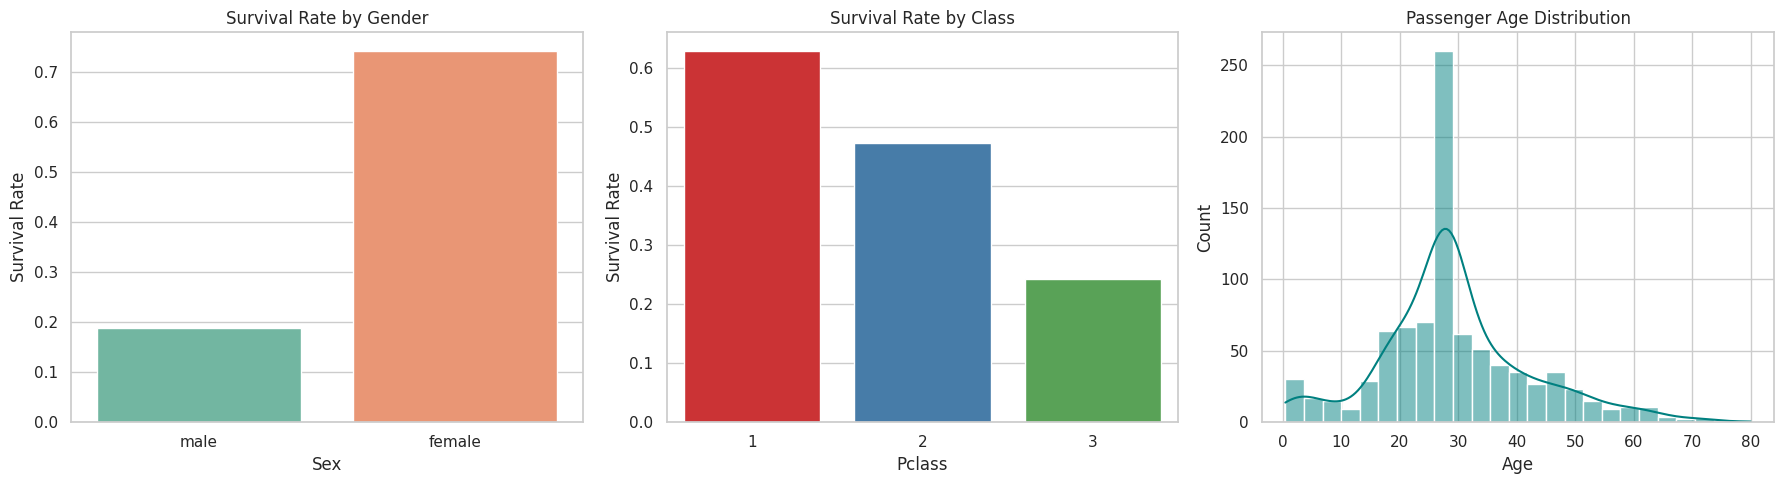

In [30]:
# Set Seaborn theme
sns.set_theme(style="whitegrid")

# Create figures side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Bar chart of survival by gender
sns.barplot(ax=axes[0], data=df, x='Sex', y='Survived', hue='Sex', legend=False, errorbar=None, palette='Set2')
axes[0].set_title('Survival Rate by Gender')
axes[0].set_ylabel('Survival Rate')

# 2. Bar chart of survival by class
sns.barplot(ax=axes[1], data=df, x='Pclass', y='Survived', hue='Pclass', legend=False, errorbar=None, palette='Set1')
axes[1].set_title('Survival Rate by Class')
axes[1].set_ylabel('Survival Rate')

# 3. Histogram of passenger ages
sns.histplot(ax=axes[2], data=df, x='Age', kde=True, bins=25, color='teal')
axes[2].set_title('Passenger Age Distribution')

plt.tight_layout()
plt.show()

📊 Titanic Survival Analysis: Executive Summary Report
Based on our data cleaning, processing, and visual explorations, here is the summary report of the survival patterns identified in the Titanic dataset:

1. Gender and Survival Rate
Female Survival Rate: 74.2%
Male Survival Rate: 18.9%
Key Finding: Females had a vastly higher rate of survival than males. This strongly supports the historical maritime protocol of prioritizing women and children during evacuations.
2. Passenger Class and Survival Rate
First Class (Pclass 1): 63.0% survival rate
Second Class (Pclass 2): 47.3% survival rate
Third Class (Pclass 3): 24.2% survival rate
Key Finding: Socioeconomic status played a major role in survival chances. Passengers traveling in First Class were almost three times more likely to survive than those in Third Class.
3. Age Group and Survival Rate
Children (0-12): 58.0% (highest survival rate among age categories)
Teenagers (13-18): 42.9%
Adults (36-60): 40.0%
Young Adults (19-35): 35.3%
Seniors (60+): 22.7% (lowest survival rate)
Key Finding: Children were heavily prioritized for lifeboats, yielding a high survival rate, whereas senior passengers had the lowest likelihood of survival.
Visualization Insights
Gender Chart: Clearly highlights the major discrepancy in survival rates between males and females.
Class Chart: Illustrates a strict step-down survival trend as the ticket class decreases.
Age Distribution: Reveals that the vast majority of passengers on board were young adults (aged between 20 and 35)